# **4.6 Dropout**
In [Section 4.5](./weight_decay.ipynb#45), we introduced the classic method of regularizing statistical models by penalizing the $L_2$ norm of the weights. From a probabilistic perspective, we can justify the validity of this technique with the following argument: We have assumed a prior distribution, namely that the values of the weights are drawn from a Gaussian distribution with a mean of 0. More intuitively, we want **the model to explore features in depth—that is, to distribute its weights across many features—rather than relying too heavily on a few potential spurious associations.**

## **4.6.1 A Fresh Look at Overfitting**
**When faced with more features and insufficient data, linear models tend to overfit. Conversely, when given more data rather than more features, linear models generally do not overfit. Unfortunately, the reliability of linear models’ generalization comes at a cost. Simply put, linear models do not account for interactions between features. For each feature, a linear model must assign a positive or negative weight while ignoring the other features.**<br><br>
This fundamental trade-off between generalizability and flexibility is described as the bias-variance trade-off. **Linear models have high bias: they can represent only a small class of functions. However, these models have low variance: they produce similar results across different random data samples.**<br><br>
Deep neural networks lie at the opposite end of the bias-variance spectrum. **Unlike linear models, neural networks are not limited to examining each feature in isolation; instead, they learn the interactions between features.** For example, a neural network might infer that the appearance of “Nigeria” and “Western Union” together in an email indicates spam, whereas their appearance separately does not.<br><br>
Even if we have far more samples than features, deep neural networks can still overfit.

## **4.6.2 Robustness to Disturbances**
Before exploring generalization, let’s first define what constitutes a “good” predictive model. **We expect a “good” predictive model to perform well on unseen data: Classical generalization theory holds that, to minimize the gap between training and testing performance, we should aim for simple models.** Simplicity manifests as lower dimensionality, a point we explored in [Section 4.4](./model_selection_under_over_fit.ipynb#44-model-selection-underfitting-and-overfitting) when discussing polynomial functions in linear models. Furthermore, as we saw in [Section 4.5](./weight_decay.ipynb#45-weight-decay) when discussing weight decay ($L_2$ regularization), the norm of the parameters also serves as a useful measure of simplicity.<br><br>
**Another aspect of simplicity is smoothness—that is, a function should not be sensitive to small changes in its input.** For example, when classifying images, we expect that adding some random noise to the pixels should have virtually no effect.In 1995, Christopher Bishop proved that training with input noise is equivalent to Tikhonov regularization (Bishop, 1995). This work mathematically established the connection between “requiring the function to be smooth” and “requiring the function to be adaptive to random noise in the input.”<br><br>
Then, in 2014, Srivastava et al. (2014) proposed an idea on how to apply Bishop’s concept to the internal layers of a network: **during training, they suggested injecting noise into each layer of the network before computing the subsequent layer. This is because, when training a deep, multi-layer network, injecting noise only enhances the smoothness of the input-output mapping.**<br><br>
It should be noted that the original paper on the Temporary Retreat Method drew an analogy to sexual reproduction: **overfitting in neural networks is related to each layer depending on the activation values of the previous layer, a phenomenon referred to as “co-adaptation.”** The authors argue that the Temporary Retreat Method disrupts co-adaptation, just as sexual reproduction disrupts co-adapted genes.<br><br>
So the key challenge is how to inject this noise. **One idea is to inject noise in an unbiased manner. This way, when the other layers are held fixed, the expected value of each layer is equal to the value it would have without noise.**<br><br>
In Bishop’s work, he adds Gaussian noise to the inputs of a linear model. In each training iteration, he adds noise sampled from a distribution with mean zero, $\epsilon \sim N(0,\sigma^{2})$, to the input $x$, thereby generating a perturbed point $x′=x+\epsilon$, with the expectation that $E[x′]=x$.<br><br>
**In standard backpropagation regularization, bias in each layer is eliminated by normalizing the scores of the retained (non-discarded) nodes. In other words, each intermediate activation value $h$ is replaced by a random variable $h'$ with a backpropagation probability $p$, as shown below**:
##### **(4.6.1)**
$$
h'=
\begin{cases}
0 & The \ probability \ is \ p \\
\frac{h}{1-p} & other \ cases
\end{cases}
$$
According to the design of this model, its expected value remains constant, that is, $E[h'] = h$.

## **4.6.3 The Method of Temporary Withdrawal in Practice**
Recall the multilayer perceptron in [Figure 4.1.1](./multi_layer_perceptron.ipynb#Fig411), which has one hidden layer and five hidden units. When we apply the backpropagation algorithm to the hidden layer—setting the hidden units to zero with probability p—the result can be viewed as a network consisting only of a subset of the original neurons. For example, in [Figure 4.6.1](#Fig461), h2 and h5 have been removed; therefore, the calculation of the output no longer depends on h2 or h5, and their respective gradients will also disappear during backpropagation. In this way, the calculation of the output layer cannot rely excessively on any single element of h1, ..., h5.
##### **Fig(4.6.1)**
![Droupout Illustration](../../images/picture4_6_1.png)<br><br>
**Generally, we do not use the backpropagation method during testing. Given a trained model and a new sample, we do not discard any nodes, so normalization is not necessary. However, there are some exceptions: some researchers use the backpropagation method during testing to estimate the “uncertainty” of a neural network’s predictions. If the predictions obtained after applying many different backpropagation methods are consistent, we can say that the network performs more stably.**

## **4.6.4 Implementation from Scratch**
To implement a single-layer backpropagation function, we draw samples from the uniform distribution $U[0,1]$, with the number of samples equal to the dimension of that layer of the neural network. We then retain the nodes corresponding to samples greater than $p$ and discard the rest.<br><br>
In the code below, we implement **the `dropout_layer` function, which discards elements from the input tensor `X` with a probability equal to the dropout rate and rescales the remaining elements as described above: by dividing the remaining elements by 1.0 minus the dropout rate.**

In [1]:
import torch
from torch import nn
from d2l import torch as d2l

def dropout_layer(X, dropout):
    assert 0 <= dropout <= 1
    # In this situation, all elements are discarded.
    if dropout == 1:
        return torch.zeros_like(X)
    # In this case, all elements are retained.
    if dropout == 0:
        return X
    mask = (torch.rand(X.shape) > dropout).float()
    return mask * X / (1.0 - dropout)

We can test the `dropout_layer` function through the following examples. We will apply dropout to the input X with dropout probabilities of 0, 0.5, and 1, respectively.

In [2]:
X = torch.arange(16, dtype=torch.float32).reshape((2, 8))
print(X)
print(dropout_layer(X, 0.))
print(dropout_layer(X, 0.5))
print(dropout_layer(X, 1.))

tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
tensor([[ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11., 12., 13., 14., 15.]])
tensor([[ 0.,  0.,  0.,  0.,  0., 10., 12., 14.],
        [16., 18.,  0., 22., 24.,  0.,  0., 30.]])
tensor([[0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0.]])


### **Define model parameters**
Similarly, we use the Fashion-MNIST dataset introduced in [Section 3.5](../../chapter_linear_neural_network/content/image_classification_dataset.ipynb#35-image-classification-dataset). We define a multilayer perceptron with two hidden layers, each containing 256 units.

In [3]:
num_inputs, num_outputs, num_hidden1, num_hidden2 = 784, 10, 256, 256

### **Define Model**
We can apply dropout to the output of each hidden layer (after the activation function) and can set different dropout rates for each layer: **a common trick is to use a lower dropout rate closer to the input layer**. In the model below, the dropout rates for the first and second hidden layers are set to 0.2 and 0.5, respectively, and dropout is only active during training.

In [4]:
dropout1, dropout2 = 0.2, 0.5

class Net(nn.Module):
    def __init__(self, num_inputs, num_outputs, num_hidden1, num_hidden2, is_training=True):
        super(Net, self).__init__()
        self.num_inputs = num_inputs
        self.training = is_training
        self.lin1 = nn.Linear(num_inputs, num_hidden1)
        self.lin2 = nn.Linear(num_hidden1, num_hidden2)
        self.lin3 = nn.Linear(num_hidden2, num_outputs)
        self.relu = nn.ReLU()

    def forward(self, X):
        H1 = self.relu(self.lin1(X.reshape((-1, self.num_inputs))))
        # Dropout is only used when training the model.
        if self.training:
            # Add a dropout layer after the first fully connected layer
            H1 = dropout_layer(H1, dropout1)
        H2 = self.relu(self.lin2(H1))
        if self.training:
            # Add a dropout layer after the second fully connected layer
            H2 = dropout_layer(H2, dropout2)
        out = self.lin3(H2)
        return out

net = Net(num_inputs, num_outputs, num_hidden1, num_hidden2, is_training=True)

### **Training and testing**

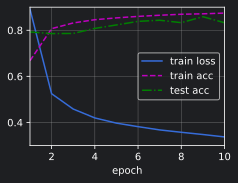

In [6]:
num_epochs, lr, batch_size = 10, 0.5, 256
loss = nn.CrossEntropyLoss(reduction='none')
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size, root='../../data')
trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

## **4.6.5 Concise Implementation**
For the high-level APIs of deep learning frameworks, we just need to add a Dropout layer after each fully connected layer and pass the dropout probability as the only parameter to its constructor. **During training, the Dropout layer will randomly drop outputs from the previous layer according to the specified dropout probability (basically the input to the next layer). During testing, the Dropout layer just passes the data through.**

In [7]:
net = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    # Add a dropout layer after the first fully connected layer
    nn.Dropout(dropout1),
    nn.Linear(256, 256),
    nn.ReLU(),
    # Add a dropout layer after the second fully connected layer
    nn.Dropout(dropout2),
    nn.Linear(256, 10),
)

def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=256, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=256, out_features=256, bias=True)
  (5): ReLU()
  (6): Dropout(p=0.5, inplace=False)
  (7): Linear(in_features=256, out_features=10, bias=True)
)

Next, we'll train and test the model.

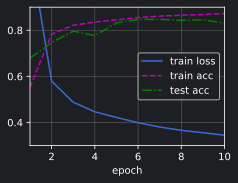

In [8]:
trainer = torch.optim.SGD(net.parameters(), lr=lr)
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

## **Summary**
* **Dropout temporarily turns off some neurons while calculating each hidden layer during forward propagation.**
* Dropout can help prevent overfitting, and it's usually used together with controlling the dimension and size of the weight vectors.
* **The dropout method replaces the activation value h with a random variable that has an expected value of h.**
* Dropout is only used during training.